# 06 — Robustness Checks

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Validate causal estimates through placebo tests, sensitivity analysis, LOO  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Robustness tables and placebo plots

---

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.causal_models import run_ols_baseline, run_dml, run_causal_forest
from src.robustness import (
    placebo_test_time, placebo_test_outcome,
    leave_one_out_analysis, alternative_specifications,
    compute_e_value, oster_delta
)
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
set_publication_style()

panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape}")

Panel: (7630, 74)


In [2]:
# Setup common variables
OUTCOME = "log_co2"
TREATMENT = [c for c in panel.columns if c.startswith("treat_")][0]  # primary treatment

# co2_lag1 removed from the covariate ladder (see Notebook 05 cell 3 for the
# full rationale): it is a "bad control" for any post-adoption observation
# more than one year past treatment, since last year's CO2 was itself
# measured under treatment. "Baseline" here is now identical to Notebook
# 05's Core specification (population, GDP per capita, urbanization), so
# the main cross-sectional comparison (Table 3) and this robustness ladder's
# middle rung are the same specification and sample.
potential_covariates = [
    "population", "gdp_per_capita", "urban_pct"
]
COVARIATES = [c for c in potential_covariates if c in panel.columns]

print(f"Treatment: {TREATMENT}")
print(f"Covariates: {len(COVARIATES)}")

Treatment: treat_carbon_pricing
Covariates: 3


---
## 6.1 — Placebo Test (Time)

6.1 — Temporal Placebo Test


 shift         label  estimate  ci_lower  ci_upper  std_error  n_obs
    -5 Placebo (t-5) -0.107253 -0.189693 -0.024814   0.042062   5689
    -3 Placebo (t-3) -0.112880 -0.189852 -0.035908   0.039272   5689
    -1 Placebo (t-1) -0.109493 -0.184213 -0.034772   0.038123   5689
     0        Actual -0.303947 -0.431566 -0.176329   0.065113   6845


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\placebo_test_time.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\placebo_test_time.pdf


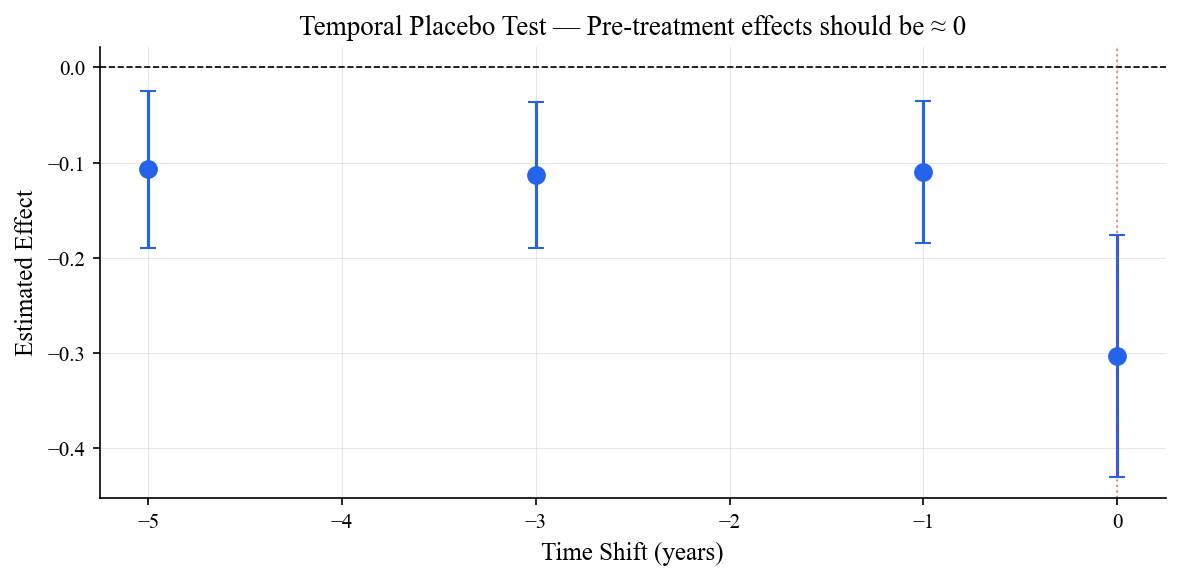

In [3]:
print("=" * 60)
print("6.1 — Temporal Placebo Test")
print("=" * 60)

placebo_time = placebo_test_time(
    panel, run_ols_baseline, TREATMENT, OUTCOME, COVARIATES,
    placebo_shifts=[-5, -3, -1, 0],
    fe_cols=["iso3", "year"]
)
print(placebo_time.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
valid = placebo_time.dropna(subset=["estimate"])
colors = [COLORS["primary"] if s == 0 else COLORS["neutral"] for s in valid["shift"]]
ax.errorbar(valid["shift"], valid["estimate"],
            yerr=[valid["estimate"] - valid["ci_lower"], valid["ci_upper"] - valid["estimate"]],
            fmt="o", capsize=4, color=COLORS["primary"], markersize=8)
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(0, color=COLORS["danger"], linestyle=":", linewidth=1, alpha=0.5)
ax.set_xlabel("Time Shift (years)")
ax.set_ylabel("Estimated Effect")
ax.set_title("Temporal Placebo Test — Pre-treatment effects should be ≈ 0")
plt.tight_layout()
save_figure(fig, "placebo_test_time")
plt.show()

---
## 6.2 — Leave-One-Out Analysis

---
## 6.1b — Placebo Test (Outcome)

In [4]:
print("=" * 60)
print("6.1b - Outcome Placebo Test")
print("=" * 60)

# If carbon/climate policy has a genuine causal effect on emissions, it should
# NOT show a comparably strong effect on outcomes it plausibly does not drive in
# the short run (urbanization rate, trade openness). A significant "effect" on
# these placebo outcomes would suggest the DML/OLS specification is picking up
# confounding rather than a genuine treatment effect.
placebo_outcomes = [c for c in ["urban_pct", "trade_pct_gdp"] if c in panel.columns]

placebo_outcome_results = placebo_test_outcome(
    panel, run_ols_baseline, TREATMENT, placebo_outcomes, COVARIATES,
    fe_cols=["iso3", "year"]
)
print(placebo_outcome_results.to_string(index=False))
placebo_outcome_results.to_csv(TABLE_DIR / "placebo_test_outcome.csv", index=False)


6.1b - Outcome Placebo Test


      outcome  estimate  ci_lower  ci_upper  std_error  significant
    urban_pct -1.380242 -2.771257  0.010772   0.709714        False
trade_pct_gdp  6.747888 -1.655670 15.151445   4.287608        False


6.2 — Leave-One-Out Stability


           dropped  estimate  ci_lower  ci_upper  n_obs
None (Full Sample) -0.303947 -0.431566 -0.176329   6845
               ABW -0.303498 -0.430960 -0.176035   6810
               AFG -0.302002 -0.429765 -0.174240   6820
               AGO -0.304854 -0.432508 -0.177201   6810
               AIA -0.303947 -0.431566 -0.176329   6845
               ALB -0.306408 -0.437126 -0.175690   6810
               AND -0.305089 -0.433076 -0.177101   6810
               ARE -0.306377 -0.434572 -0.178182   6810
               ARG -0.306161 -0.436179 -0.176142   6810
               ARM -0.303543 -0.431404 -0.175682   6810
               ATA -0.303947 -0.431566 -0.176329   6845


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\leave_one_out.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\leave_one_out.pdf


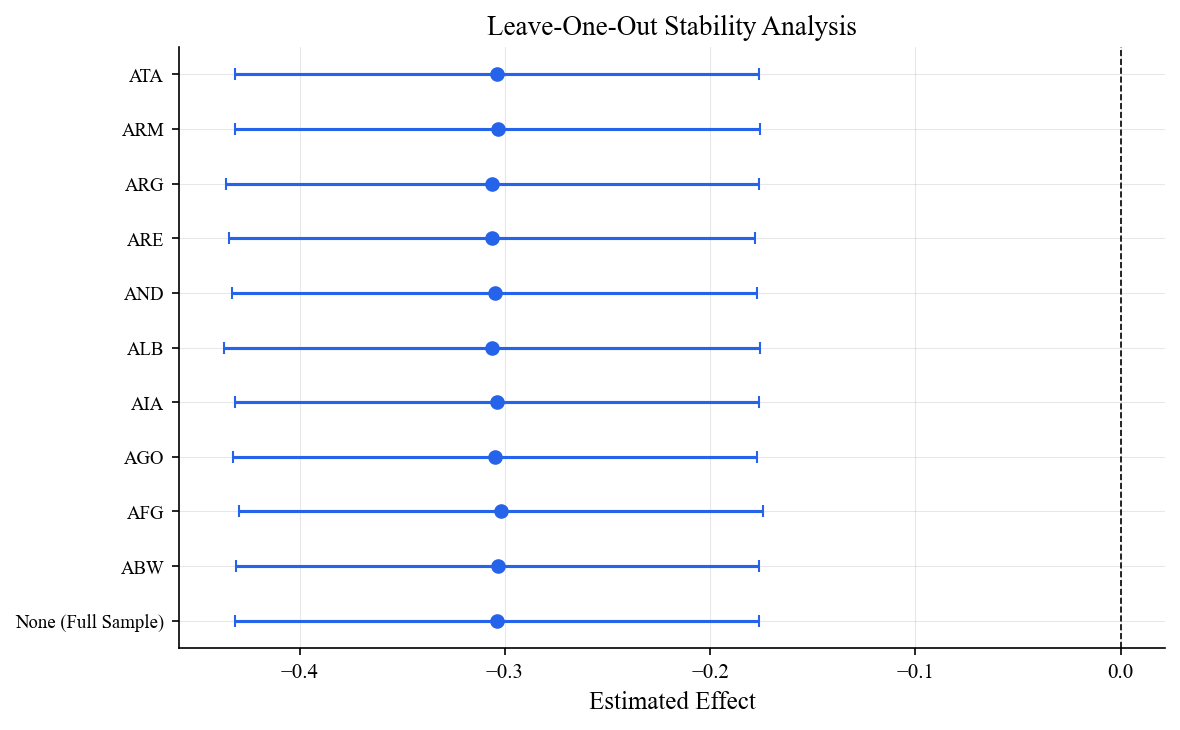

In [5]:
print("=" * 60)
print("6.2 — Leave-One-Out Stability")
print("=" * 60)

loo_results = leave_one_out_analysis(
    panel, run_ols_baseline, OUTCOME, TREATMENT, COVARIATES, top_n=10,
    fe_cols=["iso3", "year"]
)

if len(loo_results) > 0:
    print(loo_results.to_string(index=False))
    
    # Plot
    fig, ax = plt.subplots(figsize=(8, 5))
    y_pos = range(len(loo_results))
    colors = [COLORS["primary"] if d == "None (Full Sample)" else COLORS["neutral"]
              for d in loo_results["dropped"]]
    ax.errorbar(loo_results["estimate"], y_pos,
                xerr=[loo_results["estimate"] - loo_results["ci_lower"],
                      loo_results["ci_upper"] - loo_results["estimate"]],
                fmt="o", capsize=3, color=COLORS["primary"])
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(loo_results["dropped"], fontsize=9)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Estimated Effect")
    ax.set_title("Leave-One-Out Stability Analysis")
    plt.tight_layout()
    save_figure(fig, "leave_one_out")
    plt.show()

---
## 6.3 — Alternative Specifications

In [6]:
print("=" * 60)
print("6.3 — Alternative Specifications")
print("=" * 60)

# Define different covariate sets
extended_cols = COVARIATES + ["regulatory_quality", "renewables_share_energy"]
extended_cols = [c for c in extended_cols if c in panel.columns]

specs = {
    "Minimal": [c for c in ["gdp_per_capita", "population"] if c in panel.columns],
    "Baseline": COVARIATES,
    "Extended": extended_cols,
}

# Filter out empty specs
specs = {k: v for k, v in specs.items() if len(v) > 0}

alt_results = alternative_specifications(
    panel, run_ols_baseline, OUTCOME, TREATMENT, specs,
    fe_cols=["iso3", "year"]
)

if len(alt_results) > 0:
    print(alt_results.to_string(index=False))
    alt_results.to_csv(TABLE_DIR / "alternative_specifications.csv", index=False)
    print("\n Robustness checks complete")
    print("  Proceed to Notebook 07: Results Visualization")

6.3 — Alternative Specifications


specification  n_covariates  estimate  ci_lower  ci_upper  std_error  n_obs
      Minimal             2 -0.340550 -0.473610 -0.207489   0.067889   6845
     Baseline             3 -0.303947 -0.431566 -0.176329   0.065113   6845
     Extended             5 -0.029197 -0.126775  0.068381   0.049785   2028

 Robustness checks complete
  Proceed to Notebook 07: Results Visualization


---
## 6.4 — Sensitivity to Unobserved Confounding

In [7]:
print("=" * 60)
print("6.4 - Sensitivity to Unobserved Confounding")
print("=" * 60)

# E-value: minimum confounding strength (risk-ratio scale) needed to fully
# explain away the DML point estimate / move the CI to include the null.
dml_main = run_dml(panel, OUTCOME, TREATMENT, COVARIATES)
ev = compute_e_value(dml_main.estimate, dml_main.ci_lower, dml_main.ci_upper)
print(f"DML estimate: {dml_main.estimate:.4f}  95% CI [{dml_main.ci_lower:.4f}, {dml_main.ci_upper:.4f}]")
print(f"Implied risk ratio: {ev['rr']:.3f}")
print(f"E-value (point estimate): {ev['e_value_point']:.3f}")
print(f"E-value (CI bound nearest null): {ev['e_value_ci']:.3f}")

# Oster's delta: uses the Baseline -> Extended specification ladder already
# built in Section 6.3, comparing how much the coefficient moves relative to
# how much R-squared moves when governance/energy-mix covariates are added.
if "Baseline" in specs and "Extended" in specs and specs["Extended"] != specs["Baseline"]:
    r2_full_est = run_ols_baseline(panel, OUTCOME, TREATMENT, specs["Extended"], fe_cols=["iso3", "year"])
    r_max = 1.3 * r2_full_est.additional_info["r2"]
    delta_result = oster_delta(
        panel, run_ols_baseline, OUTCOME, TREATMENT,
        restricted_covariates=specs["Baseline"], full_covariates=specs["Extended"],
        r_max=r_max, fe_cols=["iso3", "year"],
    )
    print()
    print(f"Oster's delta (Baseline -> Extended): {delta_result['delta']:.3f}")
    print(f"  beta_restricted={delta_result['beta_restricted']:.4f}, beta_full={delta_result['beta_full']:.4f}")
    print(f"  r2_restricted={delta_result['r2_restricted']:.4f}, r2_full={delta_result['r2_full']:.4f}, r_max={r_max:.4f}")
    print("  |delta| >= 1 conventionally indicates the result is unlikely to be driven entirely")
    print("  by omitted-variable bias, relative to the observed selection on included covariates.")
else:
    delta_result = {"delta": float("nan")}
    print("Extended specification not available or identical to Baseline; skipping Oster's delta.")

sensitivity_summary = pd.DataFrame([{
    "treatment": TREATMENT,
    "dml_estimate": dml_main.estimate,
    "dml_ci_lower": dml_main.ci_lower,
    "dml_ci_upper": dml_main.ci_upper,
    "e_value_point": ev["e_value_point"],
    "e_value_ci": ev["e_value_ci"],
    "oster_delta": delta_result["delta"],
}])
sensitivity_summary.to_csv(TABLE_DIR / "table_sensitivity.csv", index=False)
print()
print("Saved: table_sensitivity.csv")
print()
print(" Robustness checks complete")
print("  Proceed to Notebook 07: Results Visualization")


6.4 - Sensitivity to Unobserved Confounding


DML estimate: -0.0225  95% CI [-0.0819, 0.0370]
Implied risk ratio: 0.978
E-value (point estimate): 1.175
E-value (CI bound nearest null): 1.000



Oster's delta (Baseline -> Extended): 0.002
  beta_restricted=-0.3039, beta_full=-0.0292
  r2_restricted=0.9830, r2_full=0.9893, r_max=1.2860
  |delta| >= 1 conventionally indicates the result is unlikely to be driven entirely
  by omitted-variable bias, relative to the observed selection on included covariates.

Saved: table_sensitivity.csv

 Robustness checks complete
  Proceed to Notebook 07: Results Visualization
